In [5]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
import fit_lib as fit
import BM29_lib as BM29
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["text.usetex"] = False

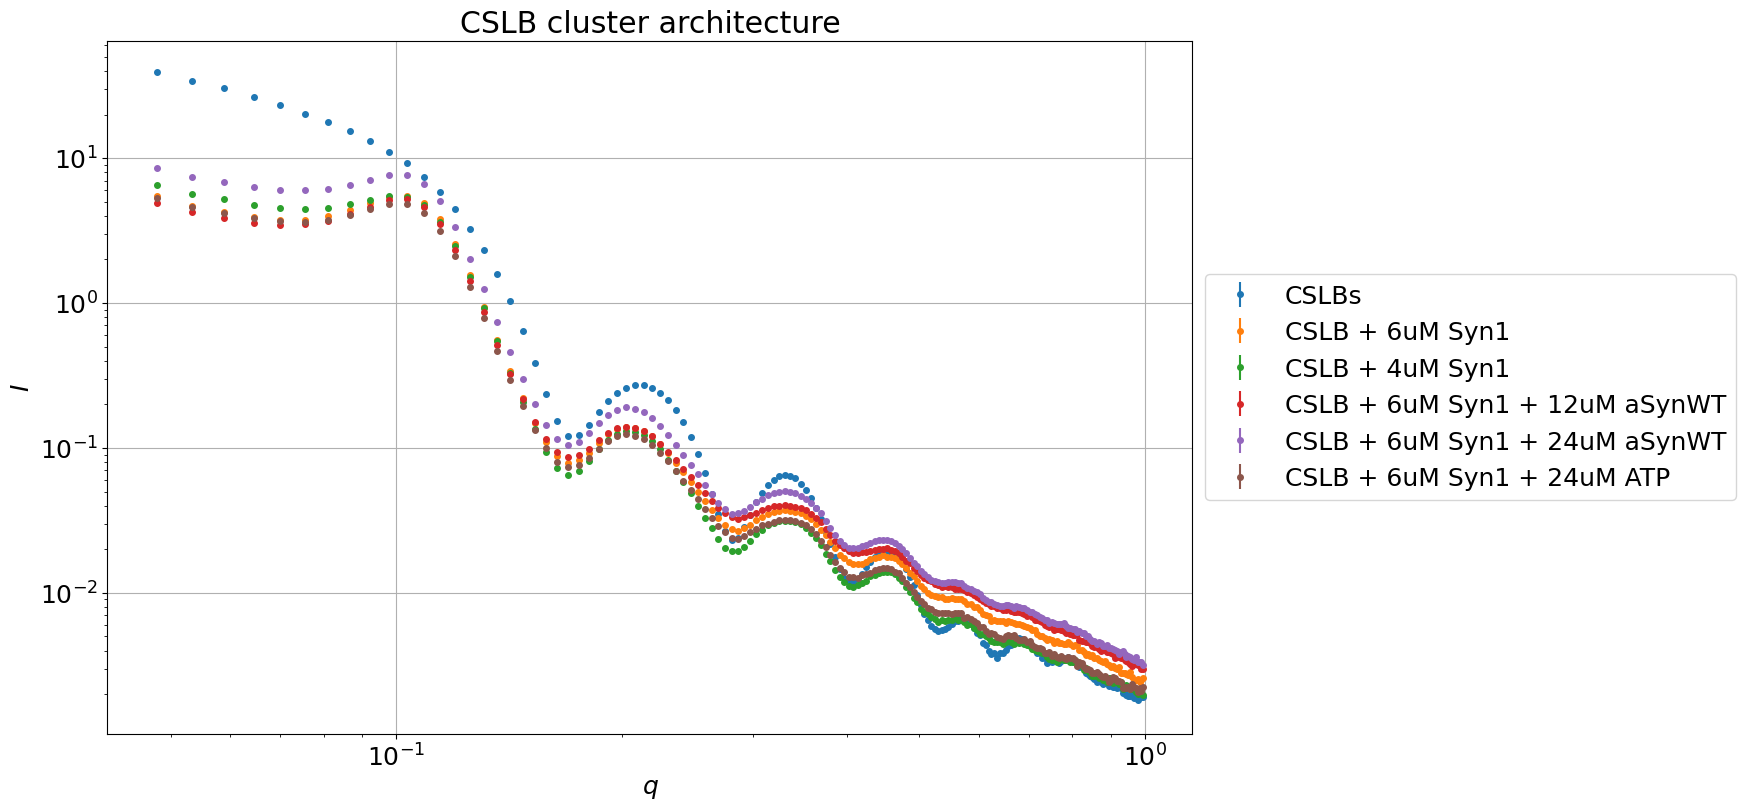

In [6]:
title = "CSLB cluster architecture"

who = [
    # "BXII_S2",
    # "BXIII_S1", #: "BXIII_S1_23nM_SVs",
    "BXIII_S2", #: "BXIII_S2_60%_CSLB",
    # "BXIII_S3", #: "BXIII_S3_3uM_Syn1",

    # "BXIII_S4", #: "BXIII_S4_15mM_LV4_4uM_Syn1",
    # "BXIII_S5", #: "BXIII_S5_15mM_LV4_6uM_Syn1",
    # "BXIII_S6", #: "BXIII_S6_15mM_LV4_6uM_Syn1_24uM_aSynWT",

    "BXIII_S11", #: "BXIII_S11_60%_CSLB_6uM_Syn1",
    "BXIII_S12", #: "BXIII_S12_60%_CSLB_4uM_Syn1",
    "BXIII_S13", #: "BXIII_S13_60%_CSLB_6uM_Syn1_12uM_aSynWT",
    "BXIII_S14", #: "BXIII_S14_60%_CSLB_6uM_Syn1_24uM_aSynWT",

    # "BXIV_S1", #: "BXIV_S1_15mM_LV4_6uM_Syn1_24uM_ATP",
    "BXIV_S3" #: "BXIV_S3_60%_CSLB_6uM_Syn1_24uM_ATP"
]

BM29.plot_together(who, title, min_cutoff=0, max_cutoff=1)

<>:56: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
<>:56: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
C:\Users\riko05\AppData\Local\Temp\ipykernel_21352\786377497.py:56: SyntaxWarning: "\_" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\_"? A raw string is also an option.
  plt.ylabel('$(I(q) - I_{Syn1\_pure}) \ / \ I_{CSLB\_pure}$')


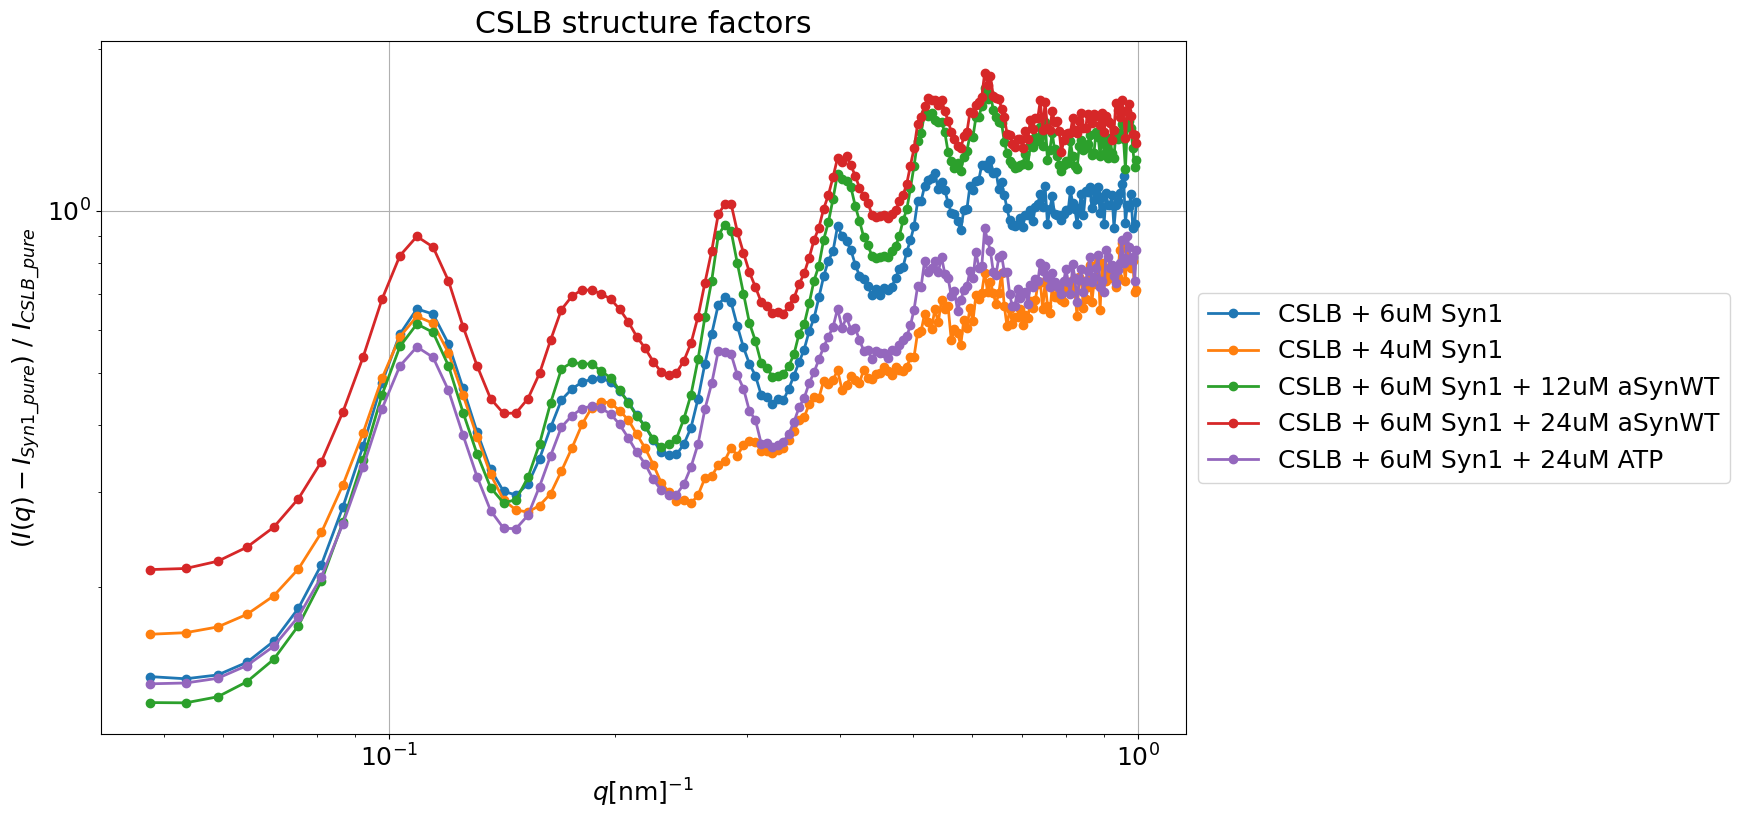

In [7]:
# Plot strucure factor with Syn1 subtraction
title = "CSLB structure factors"
Syn1_pure = "BXIII_S3"
CSLB_pure = "BXIII_S2"
prot_samples = ["BXIII_S11", #: "BXIII_S11_60%_CSLB_6uM_Syn1",
                "BXIII_S12", #: "BXIII_S12_60%_CSLB_4uM_Syn1",
                "BXIII_S13", #: "BXIII_S13_60%_CSLB_6uM_Syn1_12uM_aSynWT",
                "BXIII_S14", #: "BXIII_S14_60%_CSLB_6uM_Syn1_24uM_aSynWT"
                "BXIV_S3" #: "BXIV_S3_60%_CSLB_6uM_Syn1_24uM_ATP"
]

sample = Syn1_pure
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr_Poisson = np.loadtxt(sub_dat_path, unpack=True)
        mask = (q >= 0) & (q <= 1)
        q_Syn1_pure    = q[mask]
        I_Syn1_pure    = I[mask]
        Ierr_Poisson_Syn1_pure = Ierr_Poisson[mask]

sample = CSLB_pure
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr_Poisson = np.loadtxt(sub_dat_path, unpack=True)
        mask = (q >= 0) & (q <= 1)
        q_CSLB_pure    = q[mask]
        I_CSLB_pure    = I[mask]
        Ierr_Poisson_CSLB_pure = Ierr_Poisson[mask]

plt.figure(figsize=(14,9))
for sample in prot_samples:
    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for dir_name in dir_names:
        if dir_name[:-13].endswith(sample):
            sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
            q, I, Ierr_Poisson = np.loadtxt(sub_dat_path, unpack=True)
            mask = (q >= 0) & (q <= 1)
            q    = q[mask]
            I    = I[mask]
            Ierr_Poisson = Ierr_Poisson[mask]

            struc_factor = (I - I_Syn1_pure) / I_CSLB_pure
            plt.plot(q, struc_factor, label=BM29.nice_sample_names[sample], lw=2, marker="o", markersize=6.0)
plt.xlabel('$q [\\mathrm{nm}]^{-1}$')
# plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
plt.ylabel('$(I(q) - I_{Syn1\_pure}) \ / \ I_{CSLB\_pure}$')
plt.xscale("log")
plt.yscale("log")
plt.grid()
plt.title(title)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')



<>:56: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
<>:56: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
C:\Users\riko05\AppData\Local\Temp\ipykernel_21352\4022039180.py:56: SyntaxWarning: "\ " is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\ "? A raw string is also an option.
  plt.ylabel('$I(q) \ / \ I_{CSLB\_pure}$')


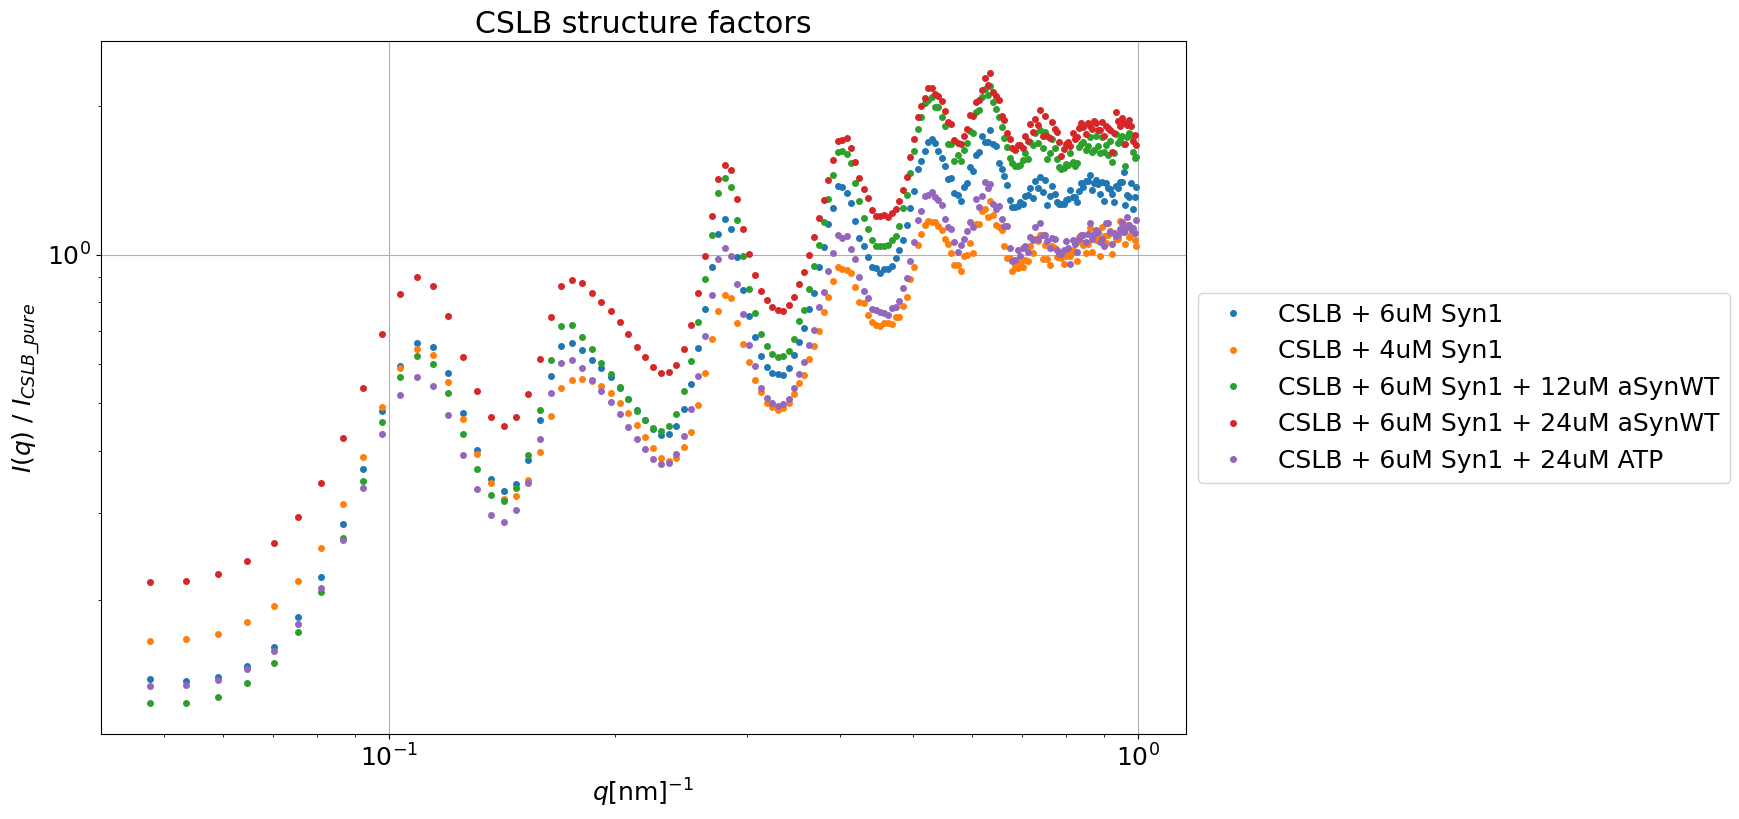

In [8]:
# Plot strucure factor without Syn1 subtraction
title = "CSLB structure factors"
Syn1_pure = "BXIII_S3"
CSLB_pure = "BXIII_S2"
prot_samples = ["BXIII_S11", #: "BXIII_S11_60%_CSLB_6uM_Syn1",
                "BXIII_S12", #: "BXIII_S12_60%_CSLB_4uM_Syn1",
                "BXIII_S13", #: "BXIII_S13_60%_CSLB_6uM_Syn1_12uM_aSynWT",
                "BXIII_S14", #: "BXIII_S14_60%_CSLB_6uM_Syn1_24uM_aSynWT"
                "BXIV_S3" #: "BXIV_S3_60%_CSLB_6uM_Syn1_24uM_ATP"
]

sample = Syn1_pure
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr_Poisson = np.loadtxt(sub_dat_path, unpack=True)
        mask = (q >= 0) & (q <= 1)
        q_Syn1_pure    = q[mask]
        I_Syn1_pure    = I[mask]
        Ierr_Poisson_Syn1_pure = Ierr_Poisson[mask]

sample = CSLB_pure
block = sample.split("_")[0]
block_path = BM29.blockpath(block)
dir_names = [x.name for x in block_path.iterdir()]
for dir_name in dir_names:
    if dir_name[:-13].endswith(sample):
        sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
        q, I, Ierr_Poisson = np.loadtxt(sub_dat_path, unpack=True)
        mask = (q >= 0) & (q <= 1)
        q_CSLB_pure    = q[mask]
        I_CSLB_pure    = I[mask]
        Ierr_Poisson_CSLB_pure = Ierr_Poisson[mask]

plt.figure(figsize=(14,9))
for sample in prot_samples:
    block = sample.split("_")[0]
    block_path = BM29.blockpath(block)
    dir_names = [x.name for x in block_path.iterdir()]
    for dir_name in dir_names:
        if dir_name[:-13].endswith(sample):
            sub_dat_path = block_path / dir_name / "avg_and_sub" / BM29.sample_dict[sample]
            q, I, Ierr_Poisson = np.loadtxt(sub_dat_path, unpack=True)
            mask = (q >= 0) & (q <= 1)
            q    = q[mask]
            I    = I[mask]
            Ierr_Poisson = Ierr_Poisson[mask]

            struc_factor = (I) / I_CSLB_pure
            plt.plot(q, struc_factor, label=BM29.nice_sample_names[sample], ls="None", marker="o", markersize=4.0)
plt.xlabel('$q [\\mathrm{nm}]^{-1}$')
# plt.ylabel('$I(q) [\\mathrm{cm}^{-1}]$')
plt.ylabel('$I(q) \ / \ I_{CSLB\_pure}$')
plt.xscale("log")
plt.yscale("log")
plt.grid()
plt.title(title)
legend = plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), alignment='left')

